In [ ]:
from IPython import display
import ultralytics
import cv2
import matplotlib.pyplot as plt
import os, glob, shutil

In [ ]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

RUNS = os.path.abspath("runs")
os.makedirs("weights", exist_ok=True)
print("ผลลัพธ์จะเก็บที่:", RUNS)

ผลลัพธ์จะเก็บที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs


In [ ]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


Setup complete  (12 CPUs, 31.7 GB RAM, 266.1/280.1 GB disk)


In [ ]:
print(open("rect.yaml", encoding="utf-8").read())

names = ["airplane", "boat", "car", "motorcycle"]
for split in ["train", "val", "test"]:
    labels = glob.glob(f"datasets/yolo_rect/{split}/labels/*.txt")
    count = [0, 0, 0, 0]
    for f in labels:
        for line in open(f).read().splitlines():
            count[int(line.split()[0])] += 1
    detail = ", ".join(f"{n}={c}" for n, c in zip(names, count))
    print(f"{split:<5} : {len(labels):>3} ภาพ | object: {detail}")

# =============================================================
#  rect.yaml : ไฟล์ตั้งค่า dataset สำหรับ "Rectangle" (Object Detection)
#  ใช้กับโมเดล  yolo26n.pt   (task = detect)
# =============================================================
# path  = โฟลเดอร์หลักของ dataset (relative กับโฟลเดอร์ที่รันคำสั่ง -> ให้รันจาก final_dip/)
# train/val/test = โฟลเดอร์ย่อยใน path  (ข้างในต้องมี images/ และ labels/)
path: ./datasets/yolo_rect
train: train
val: val
test: test

# จำนวนคลาส
nc: 4

# ชื่อคลาส  (ต้องใช้คีย์ "names" มี s นะ  ถ้าพิมพ์ "name" YOLO จะไม่อ่าน แล้วตั้งชื่อเป็น class0, class1 ...)
# ลำดับต้องตรงกับ CLASSES ใน scripts/02_anylabeling_to_yolo.py
names:
  0: airplane
  1: boat
  2: car
  3: motorcycle



train : 420 ภาพ | object: airplane=135, boat=153, car=161, motorcycle=154


val   : 120 ภาพ | object: airplane=43, boat=48, car=49, motorcycle=37


test  :  60 ภาพ | object: airplane=18, boat=35, car=28, motorcycle=16


ไฟล์: datasets/yolo_rect/train/labels\car_001.txt
2 0.403600 0.557143 0.420400 0.617493



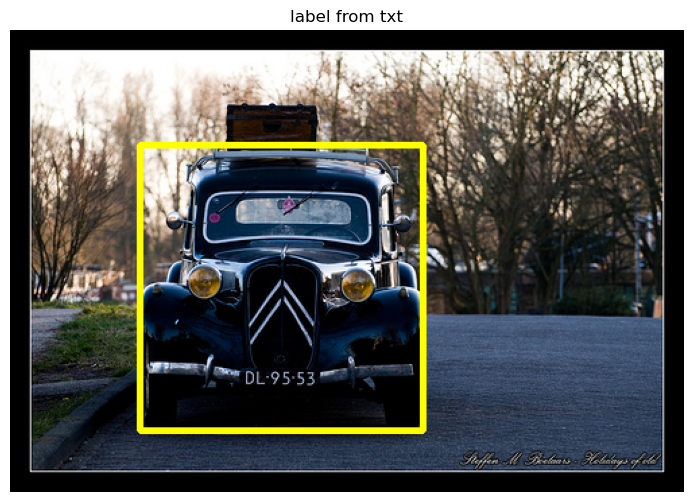

In [5]:
img_path = sorted(glob.glob("datasets/yolo_rect/train/images/car_*.jpg"))[0]
lbl_path = img_path.replace("images", "labels").replace(".jpg", ".txt")
print("ไฟล์:", lbl_path)
print(open(lbl_path).read())

im = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
h, w = im.shape[:2]
for line in open(lbl_path).read().splitlines():
    c, xc, yc, bw, bh = map(float, line.split())
    x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
    x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
    cv2.rectangle(im, (x1, y1), (x2, y2), (255, 255, 0), 3)
plt.figure(figsize=(9, 6)); plt.imshow(im); plt.title("label from txt"); plt.axis("off"); plt.show()

In [6]:
model = ultralytics.YOLO('yolo26n.yaml').load('yolo26n.pt')
print("จำนวนคลาสที่โมเดลรู้จักตอนนี้:", len(model.names))

Transferred 708/708 items from pretrained weights


จำนวนคลาสที่โมเดลรู้จักตอนนี้: 80


0: 576x640 1 4, 91.4ms


Speed: 3.6ms preprocess, 91.4ms inference, 13.8ms postprocess per image at shape (1, 3, 576, 640)


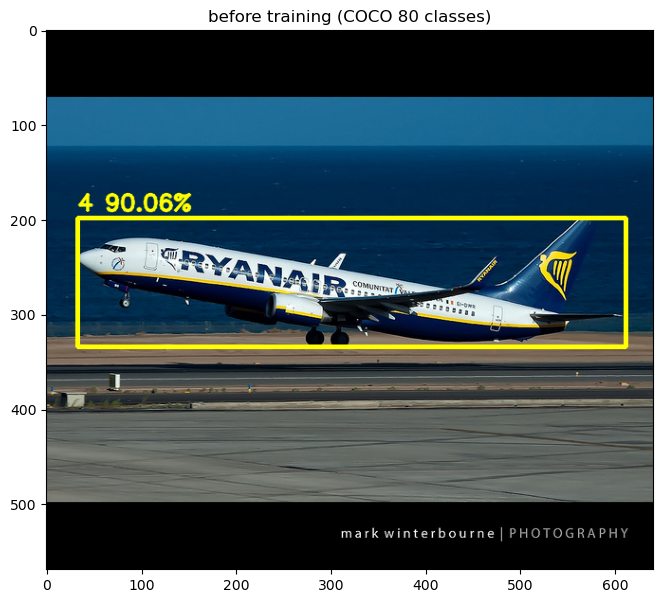

In [7]:
path = sorted(glob.glob('datasets/yolo_rect/test/images/*.jpg'))[0]
im_src = cv2.imread(path)
result = model.predict(source=im_src)
im_result = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)

for box in result[0].boxes:
    class_id = int(box.cls[0].item())
    conf = round(box.conf[0].item()*100, 2)
    display_text = f"{result[0].names[class_id]} {conf}%"
    coor = box.xyxy[0].tolist()
    coxy = [round(x) for x in coor]
    im_result = cv2.putText(im_result, display_text, (coxy[0], max(coxy[1] - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2, cv2.LINE_AA)
    im_result = cv2.rectangle(im_result, (coxy[0], coxy[1]), (coxy[2], coxy[3]), (255, 255, 0), 3)

plt.figure(figsize=(10, 7))
plt.imshow(im_result)
plt.title("before training (COCO 80 classes)")
plt.show()

In [8]:
model = ultralytics.YOLO("yolo26n.pt")
model.train(data="rect.yaml", epochs=20, imgsz=512, batch=16, patience=15, workers=2,
            device="cpu", seed=42, project=RUNS, name="rect", exist_ok=True)

shutil.copy("runs/rect/weights/best.pt", "weights/rect_best.pt")
print("saved -> weights/rect_best.pt")

New https://pypi.org/project/ultralytics/8.4.193 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=rect.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rect, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=15, perspective=0.0, plots=True, pose=12.0, pretrained=True, profi

Overriding model.yaml nc=80 with nc=4



                   from  n    params  module                                       arguments                     


...

                   car         30         49      0.823      0.569      0.752      0.577


            motorcycle         30         37      0.885       0.83      0.859      0.601


Speed: 0.5ms preprocess, 48.2ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\rect


saved -> weights/rect_best.pt


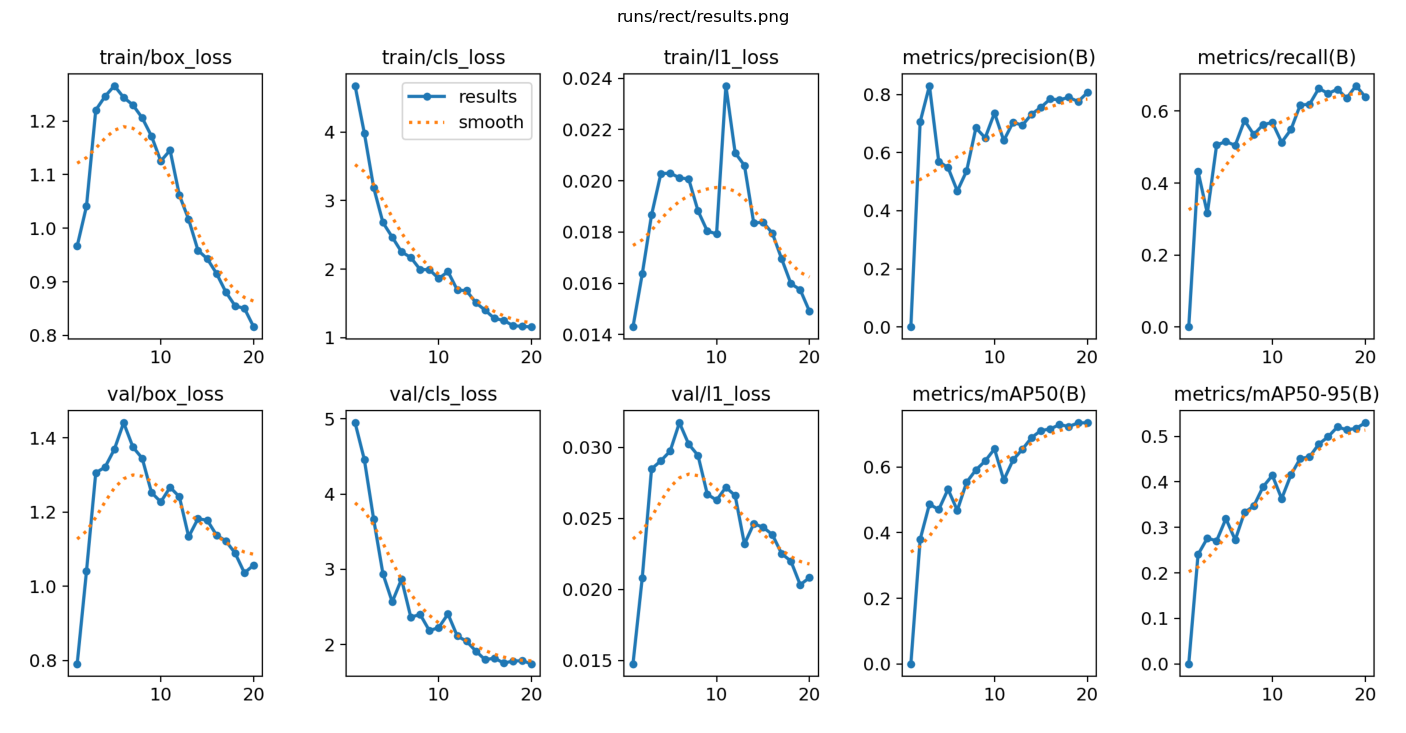

In [9]:
img = cv2.cvtColor(cv2.imread("runs/rect/results.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(18, 9)); plt.imshow(img); plt.axis("off"); plt.title("runs/rect/results.png"); plt.show()

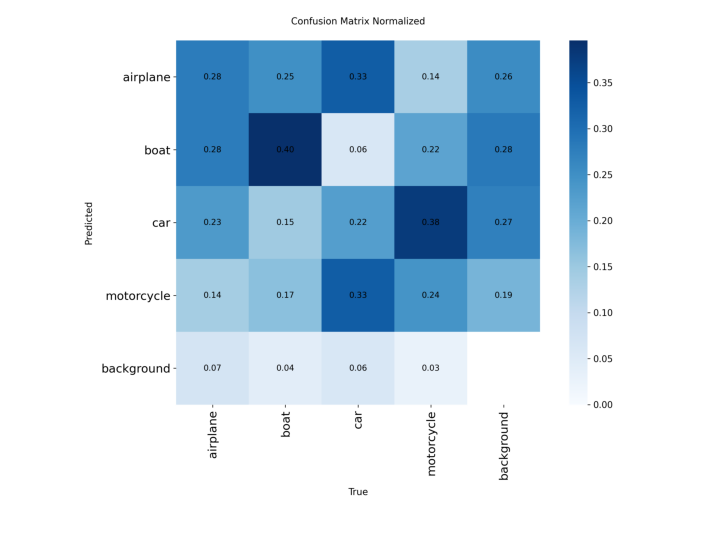

In [10]:
img = cv2.cvtColor(cv2.imread("runs/rect/confusion_matrix_normalized.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(9, 9)); plt.imshow(img); plt.axis("off"); plt.show()

In [11]:
import pandas as pd
m = ultralytics.YOLO("weights/rect_best.pt").val(data="rect.yaml", split="test", imgsz=512, device="cpu",
                                                   project=RUNS, name="rect_test", exist_ok=True)
rows = [{"class": m.names[i], "box mAP50": round(m.box.ap50[i], 3), "box mAP50-95": round(m.box.ap[i], 3)}
        for i in range(len(m.names))]
rows.append({"class": "ALL", "box mAP50": round(m.box.map50, 3), "box mAP50-95": round(m.box.map, 3)})
pd.DataFrame(rows)

Ultralytics 8.4.174  Python-3.13.9 torch-2.14.1+cpu CPU (13th Gen Intel Core i5-1334U)


YOLO26n summary (fused): 120 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs


val: Fast image access  (ping: 0.30.6 ms, read: 113.330.8 MB/s, size: 104.4 KB)



val: Scanning C:\code\ImageProcessing\yolo\yolo_lab\final_dip\datasets\yolo_rect\test\labels.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 15.7Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 3.4s/it 1.0s<10.3s

...

                   car         15         28      0.786      0.643      0.763      0.475


            motorcycle         15         16      0.913      0.875      0.922      0.648


Speed: 0.7ms preprocess, 52.6ms inference, 0.0ms loss, 2.0ms postprocess per image


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\rect_test


,class,box mAP50,box mAP50-95
0,airplane,0.978,0.879
1,boat,0.580,0.341
2,car,0.763,0.475
3,motorcycle,0.922,0.648
4,ALL,0.811,0.586


คลาสที่โมเดลรู้จักตอนนี้: {0: 'airplane', 1: 'boat', 2: 'car', 3: 'motorcycle'}


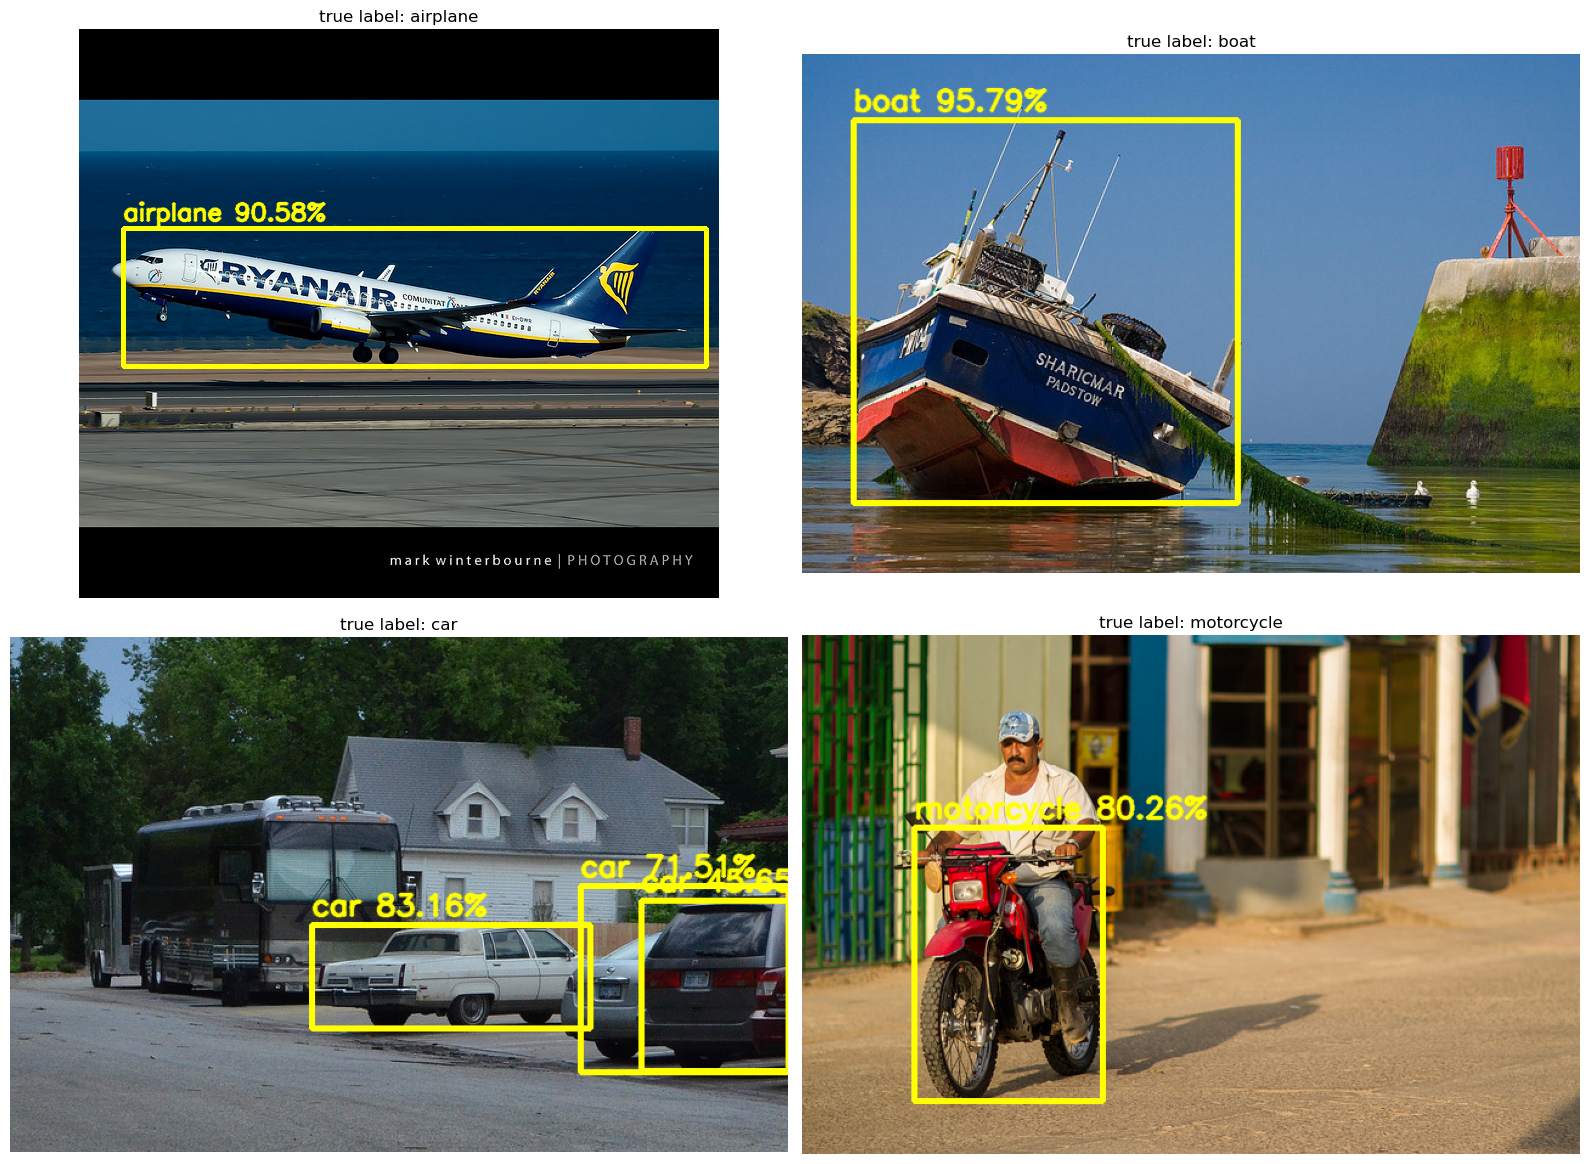

In [12]:
model = ultralytics.YOLO("weights/rect_best.pt")
print("คลาสที่โมเดลรู้จักตอนนี้:", model.names)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, cls in zip(axes.flat, ["airplane", "boat", "car", "motorcycle"]):
    path = sorted(glob.glob(f'datasets/yolo_rect/test/images/{cls}_*.jpg'))[0]
    im_src = cv2.imread(path)
    result = model.predict(source=im_src, imgsz=512, conf=0.25, verbose=False)
    im_result = cv2.cvtColor(im_src, cv2.COLOR_BGR2RGB)

    for box in result[0].boxes:
        class_id = int(box.cls[0].item())
        conf = round(box.conf[0].item()*100, 2)
        display_text = f"{result[0].names[class_id]} {conf}%"
        coor = box.xyxy[0].tolist()
        coxy = [round(x) for x in coor]
        im_result = cv2.putText(im_result, display_text, (coxy[0], max(coxy[1] - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2, cv2.LINE_AA)
        im_result = cv2.rectangle(im_result, (coxy[0], coxy[1]), (coxy[2], coxy[3]), (255, 255, 0), 3)

    ax.imshow(im_result); ax.set_title(f"true label: {cls}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [13]:
rows = []
for f in sorted(glob.glob("datasets/yolo_rect/test/images/*.jpg")):
    r = model.predict(f, imgsz=512, conf=0.25, verbose=False)[0]
    true = os.path.basename(f).rsplit("_", 1)[0]
    pred = r.names[int(r.boxes.cls[r.boxes.conf.argmax()])] if len(r.boxes) else "(ไม่เจอ)"
    rows.append({"true": true, "pred": pred, "correct": true == pred})
df = pd.DataFrame(rows)
print(f"ทายถูก {df.correct.sum()} / {len(df)} ภาพ  ({df.correct.mean()*100:.1f}%)")
pd.crosstab(df["true"], df["pred"], rownames=["จริง"], colnames=["ทาย"])

ทายถูก 53 / 60 ภาพ  (88.3%)


ทาย,(ไม่เจอ),airplane,boat,car,motorcycle
จริง,,,,,
airplane,0,15,0,0,0
boat,1,0,13,0,1
car,1,0,1,13,0
motorcycle,2,1,0,0,12


Results saved to C:\code\ImageProcessing\yolo\yolo_lab\final_dip\runs\predict_rect


runs/predict_rect/ : 60 ภาพ


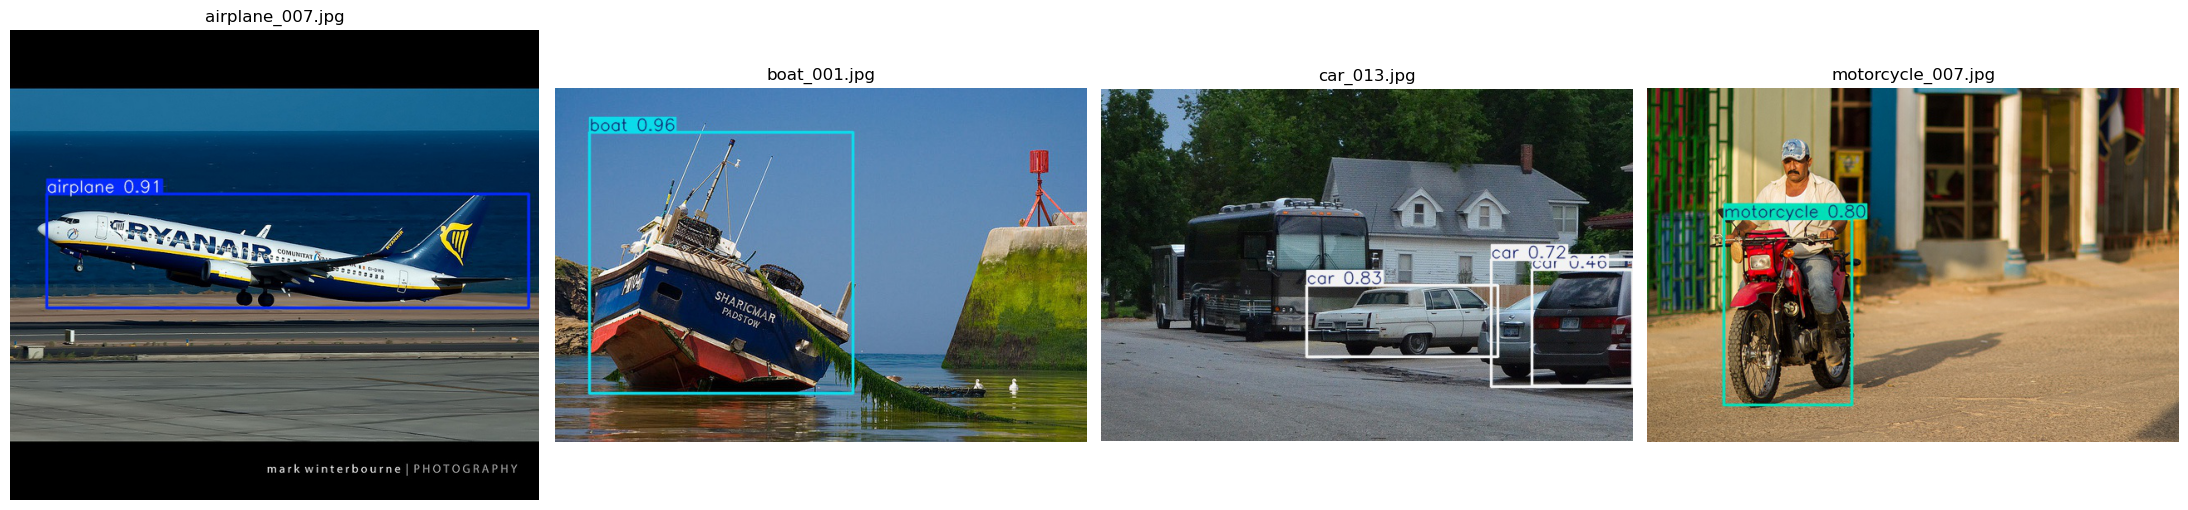

In [14]:
model.predict(source="datasets/yolo_rect/test/images", imgsz=512, conf=0.25, save=True,
              project=RUNS, name="predict_rect", exist_ok=True, verbose=False)
saved = sorted(glob.glob("runs/predict_rect/*.jpg"))
print("runs/predict_rect/ :", len(saved), "ภาพ")

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, f in zip(axes, saved[::15]):
    ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)); ax.set_title(os.path.basename(f)); ax.axis("off")
plt.tight_layout(); plt.show()